# <center>MTH 468 Project 3</center>

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd

from sklearn import linear_model as lm
from numpy.random import uniform
from scipy.special import expit



# Part 1

## a) i) and b)

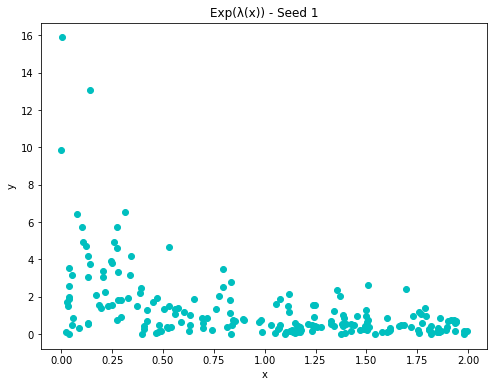

In [2]:
np.random.seed(1)
x = uniform(0, 2, 200)
c0 = -0.25
c1 = -1
y = np.random.exponential(scale=1/(-c0 - c1 * x))
plt.figure(figsize=(8,6))
plt.scatter(x, y, color='c')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Exp(λ(x)) - Seed 1')
plt.show()


## c) i)

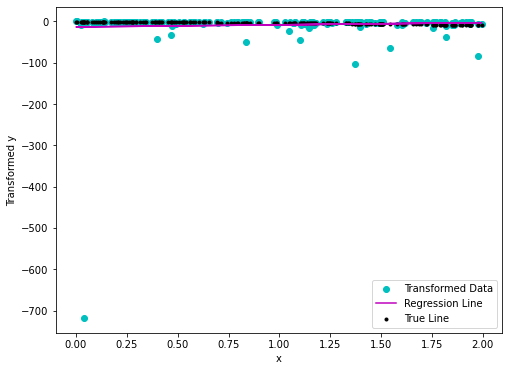

In [3]:
np.random.seed(1)

# Transform the data
y_transformed = -1 / y

# Do linear regression
linear_regression = lm.LinearRegression()
linear_model = linear_regression.fit(x.reshape(-1, 1), y_transformed)

# Plot transformed data, regression line and true line
plt.figure(figsize=(8,6))
plt.scatter(x, y_transformed, color='c', label='Transformed Data')
plt.plot(x, linear_model.predict(x.reshape(-1, 1)), color='m', label = 'Regression Line')
plt.scatter(x, -1 / (np.exp(c0 + c1*x)), color='black', label = 'True Line', marker='.')
plt.xlabel('x')
plt.ylabel('Transformed y')
plt.legend()
plt.show()


### ii)

The transformed data points seem to be very tightly clustered along the horizontal axis at point '0', except for a few outliers. This indicates that the inverse transformation has significantly reduced the variance in the y-values, except for y-values close to zero which are transformed to VERY large negative numbers.

### iii)

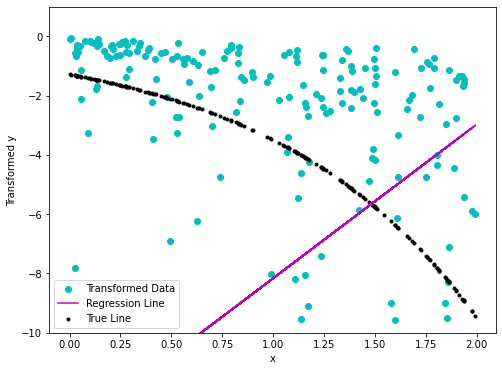

In [4]:

np.random.seed(1)
# Transform the data
y_transformed = -1 / y

# Do linear regression
linear_regression = lm.LinearRegression()
linear_model = linear_regression.fit(x.reshape(-1, 1), y_transformed)

# Plot transformed data, regression line and true line
plt.figure(figsize=(8,6))
plt.scatter(x, y_transformed, color='c', label='Transformed Data')
plt.plot(x, linear_model.predict(x.reshape(-1, 1)), color='m', label = 'Regression Line')
plt.scatter(x, -1 / (np.exp(c0 + c1*x)), color='black', label = 'True Line', marker='.')
plt.xlabel('x')
plt.ylabel('Transformed y')
plt.ylim(-10,1)
plt.legend()
plt.show()


Meanwhile, as we reduce the y-range to just from 1 to -10, we see that the true line is fit independent of the outliers however the Linear Regression line is fit taking into account the outliers. That leads to it being very innaccurate in comparison to the true line. This plot highlights the limitations of linear regression models.

### iv)

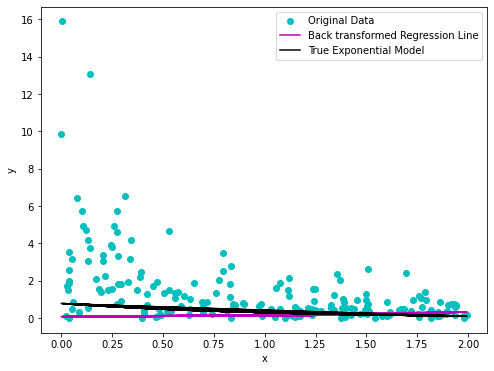

In [5]:
np.random.seed(1)

# Fit the linear model to transformed data
linear_model = lm.LinearRegression()
linear_model.fit(x.reshape(-1, 1), y_transformed)

# Make predictions on transformed scale and then back-transform them to the original scale
y_transformed_pred = linear_model.predict(x.reshape(-1, 1))
y_pred_back_transformed = -1 / y_transformed_pred

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='c', label='Original Data')
plt.plot(x, y_pred_back_transformed, color='m', label='Back transformed Regression Line')
plt.plot(x, np.exp(c0 + c1 * x), color='black', label='True Exponential Model')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


The back-transformed regression line is derived from a linear fit on a transformed scale. When back-transformed, this line captures the exponential nature of the data as well as the true line and they are very close to each other.

### d) i)

In [6]:
np.random.seed(1)

# Adding constant to predictor
exog = sm.add_constant(x)

# Fitting GLM
gamma_model = sm.GLM(y, exog, family=sm.families.Gamma(link=sm.families.links.inverse_power()))
gamma_results = gamma_model.fit()
gamma_results.summary()


~/opt/anaconda3/lib/python3.9/site-packages/statsmodels/genmod/generalized_linear_model.py:298: DomainWarning: The inverse_power link function does not respect the domain of the Gamma family.
  warnings.warn((f"The {type(family.link).__name__} link function "


<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                  200
Model:                            GLM   Df Residuals:                      198
Model Family:                   Gamma   Df Model:                            1
Link Function:          inverse_power   Scale:                         0.81917
Method:                          IRLS   Log-Likelihood:                -205.61
Date:                Fri, 19 Apr 2024   Deviance:                       204.79
Time:                        16:37:36   Pearson chi2:                     162.
No. Iterations:                     8   Pseudo R-squ. (CS):             0.4827
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1853      0.044      4.234      0.000       0.100       0.271
x1             1.0276      0.102     10.088      0.000       0.828       1.227
==============================================================================
"""

### ii)

In [7]:
gamma_results.params

array([0.1852722, 1.0276128])

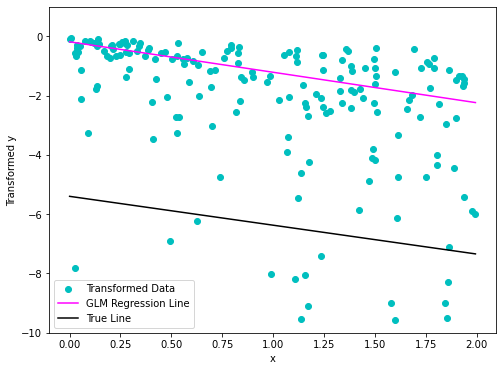

In [8]:
np.random.seed(1)
x_space = np.linspace(np.min(x), np.max(x), len(x))
predictions = gamma_results.predict(sm.add_constant(x_space))
y_transformed = -1/y

# Plotting transformed data
plt.figure(figsize=(8, 6))
plt.scatter(x, y_transformed, label='Transformed Data', c ='c')

y_pred_transformed = -1/predictions
# Plotting regression line
plt.plot(x_space, y_pred_transformed, label='GLM Regression Line', color='magenta')

# Making function for true_line
def true_line(x, coefficient, intercept):
    result = coefficient*x + intercept
    return result

# Plot true line
plt.plot(x_space, true_line(x_space, -1/gamma_results.params[1], -1/gamma_results.params[0]), label='True Line', color='black')
plt.ylim(-10, 1)
plt.xlabel('x')
plt.ylabel('Transformed y')
plt.legend()
plt.show()


The GLM Regression seems to fit more with the concentrated area of the transformed dataset. The true line seems to be taking into account the outliers as well. Both the True and the GLM Regression have a very similar slope. 

### iii)

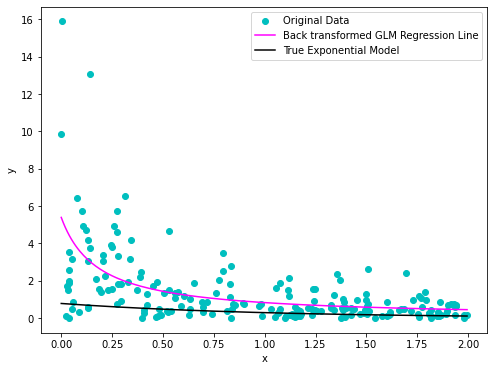

In [9]:
np.random.seed(1)
# Back-transform predictions
y_back_transformed = -1 / y_pred_transformed

# Plotting data
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label='Original Data', c='c')

# Plot GLM regression line
plt.plot(x_space, y_back_transformed, label='Back transformed GLM Regression Line', color='magenta')

# Plot true model
plt.plot(x_space, np.exp(c0 + c1 * x_space), label='True Exponential Model', color='black')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


Here, the Back transformed GLM Regression Line fits pretty closely with the True Line. It also gets closer and closer to the True Line as the x values increase. 

### iv)

- By weighting the residuals inversely to their value, the algorithm gives less importance to outliers and more to data points that are closer to the model prediction. This can lead to a more stable solution since the impact of outlier values is reduced.


- The Gaussian data has constant variance, and Poisson data has variance equal to the mean. However, exponential distributions result in residuals that are not uniformly distributed. So, some y-values can have larger absolute residuals and without weighting, these large residuals disproportionately impact the model. The weighting method works around this by weighting these outliers less.


# Part 2

### a)

In [10]:
boundary_quad = pd.read_excel("BoundaryQuad.xlsx")
boundary_quad['Score'] = (boundary_quad['Score'] == 'Pass').astype(int)
boundary_quad.head()

,Study,Sleep,Score
0,7.0,7.0,0
1,8.0,6.5,0
2,12.0,6.0,1
3,5.0,6.5,0
4,10.0,7.0,1


In [11]:
boundary_quad['Sleep2'] = boundary_quad['Sleep']**2

# Define variables
X = boundary_quad[['Study', 'Sleep', 'Sleep2']]  # Predictors
X = sm.add_constant(X)  # Add constant
y = boundary_quad['Score']  # Response

# Logistic Regression Model
model = sm.Logit(y, X)
result = model.fit()

print(result.summary())


         Current function value: 0.000000
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                  Score   No. Observations:                   14
Model:                          Logit   Df Residuals:                       10
Method:                           MLE   Df Model:                            3
Date:                Fri, 19 Apr 2024   Pseudo R-squ.:                   1.000
Time:                        16:37:37   Log-Likelihood:            -2.2275e-06
converged:                      False   LL-Null:                       -9.5607
Covariance Type:            nonrobust   LLR p-value:                 0.0002580
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       -632.9794    2.9e+04     -0.022      0.983   -5.75e+04    5.62e+04
Study         13.6663    856.610      0.016      0.987   -1665.25

~/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


### b)

In [12]:
# Define sigmoid
def sig(x):
    return 1 / (1 + np.exp(-x))

# Define loss function
def L(c_vect, x_data, y_data):
    predicted_probs = sig(np.dot(x_data, c_vect))
    
    # Compute loss and avoid log(0) by adding a small number
    loss = -np.mean(y_data * np.log(predicted_probs + 1e-8) + (1 - y_data) * np.log(1 - predicted_probs + 1e-8))
    return loss

# Define gradient function
def gradient(c_vect, x_data, y_data):
    predictions = sig(np.dot(x_data, c_vect))
    errors = predictions - y_data
    grad = np.dot(x_data.T, errors) / len(x_data)
    return grad

# Define Gradient Descent function
def gradient_descent(x_data, y_data, c_vect, alpha, eps, max_iter):
    for i in range(max_iter):
        grads = gradient(c_vect, x_data, y_data)
        c_vect = c_vect - alpha * grads
        if np.linalg.norm(grads) < eps:
            break
    return c_vect, i

# Initializing
initial_coeffs = np.array([-70, 2, 15, -1], dtype=float)
alpha = 0.01
eps = 1e-8
max_iter = 100000

# Gradient descent
optimized_coeffs, iters = gradient_descent(X, y, initial_coeffs, alpha, eps, max_iter)
print("Optimized Coefficients:", optimized_coeffs, "\n", "Iterations:", iters)


Optimized Coefficients: [-73.44128377   1.68758943  16.28651459  -1.14279652] 
 Iterations: 99999


### c)

- sig = 0.6 = 1 / (1 + exp(-x))
- 1/0.6 -1 = exp(-x)
- -ln(1/0.6 -1) = x

In [13]:
decision_threshold = -np.log((1/0.6) - 1)
print("Decision threshold value:", decision_threshold)

Decision threshold value: 0.4054651081081643


### d)

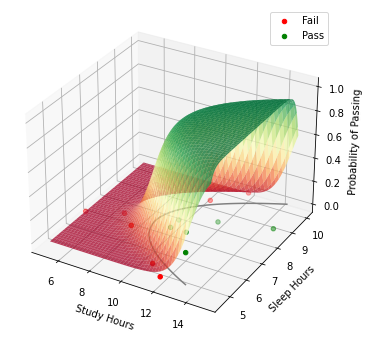

In [14]:
# Data Prep
X_study = np.linspace(boundary_quad['Study'].min(), boundary_quad['Study'].max(), 100)
X_sleep = np.linspace(boundary_quad['Sleep'].min(), boundary_quad['Sleep'].max(), 100)
X_study, X_sleep = np.meshgrid(X_study, X_sleep)
X_sleep2 = X_sleep**2

# Find probabilities
Z = sig(optimized_coeffs[0] + optimized_coeffs[1] * X_study + optimized_coeffs[2] * X_sleep + optimized_coeffs[3] * X_sleep2)

# Setup 3D Graph
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

# Plot Probability
ax.plot_surface(X_study, X_sleep, Z, cmap='RdYlGn', alpha=0.75)
ax.set_xlabel('Study Hours')
ax.set_ylabel('Sleep Hours')
ax.set_zlabel('Probability of Passing')

# Plot Data points
colors = ['red', 'green']
for i, color in enumerate(colors):
    
    # Label Pass and Fail
    mask = boundary_quad['Score'] == i
    ax.scatter(boundary_quad[mask]['Study'], boundary_quad[mask]['Sleep'], c=color, label=f'{"Pass" if i == 1 else "Fail"}')

# Plot Decision Boundary
ax.contour(X_study, X_sleep, Z, levels=[decision_threshold], colors='grey', offset=0)
ax.legend()
plt.show()


### e) i) and ii)

In [15]:
# Data inputs
inputs = [(10, 7),(11.5, 9)]   

# Calculate probabilities
results = []
for study, sleep in inputs:
    sleep2 = sleep**2
    
    z = (optimized_coeffs[0] + 
         optimized_coeffs[1] * study + 
         optimized_coeffs[2] * sleep + 
         optimized_coeffs[3] * sleep2)
    
    probability = sig(z)
    classification = "Pass" if probability > decision_threshold else "Fail"
    results.append((study, sleep, probability, classification))

for result in results:
    print("Studying =", result[0], "hours, Sleeping =", result[1], "hours, Probability =", result[2], ", Result:", result[3])


Studying = 10 hours, Sleeping = 7 hours, Probability = 0.8089470918723191 , Result: Pass
Studying = 11.5 hours, Sleeping = 9 hours, Probability = 0.49452716046532685 , Result: Pass
